# 7-day direct forecast

One LightGBM model per future day. Model 1 predicts tomorrow. Model 7 predicts the day a week ahead. They do not feed each other.

The row date is the day you are standing on. Lag 0 is that day.

| Feature group | Lags | Count |
|---|---|---|
| `day_of_week` | today only | 1 |
| `daily_cases` | 0–6 | 7 |
| `velocity` | 0–5 | 6 |
| `acceleration` | 0–4 | 5 |
| `jerk` | 0–3 | 4 |
| `pressure` | 0–6 | 7 |

That is 30 features. The test set is December 2021. A row needs all 7 future days inside the file, so the last scored forecast date is 24 December.

`forecast_7day.py` holds the steps. Change `DATA_PATH` and `TEST_START` there when the file or the holdout month changes.


## 1. Feature table

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

here = Path.cwd()
if (here / "forecast_7day.py").exists():
    sys.path.insert(0, str(here))
else:
    sys.path.insert(0, str(here / "Dhruvesh" / "training"))

from forecast_7day import (
    DATA_PATH,
    TEST_START,
    build_supervised,
    feature_importance,
    fit_models,
    load_panel,
    predict_all,
    score,
    split_by_date,
)

panel = load_panel(DATA_PATH)
frame, feature_columns, target_columns = build_supervised(panel)
print(f"{len(feature_columns)} features")
print(feature_columns)
print()
print(f"Rows ready for a model: {len(frame):,}")
print(frame.date.min().date(), "to", frame.date.max().date())

one_zip = frame.zipcode.iloc[0]
preview_columns = [
    "zipcode", "date", "day_of_week",
    "cases_lag_0", "cases_lag_6",
    "velocity_lag_0", "velocity_lag_5",
    "acceleration_lag_0", "acceleration_lag_4",
    "jerk_lag_0", "jerk_lag_3",
    "pressure_lag_0", "pressure_lag_6",
    "target_day_1", "target_day_7",
]
frame.loc[frame.zipcode.eq(one_zip), preview_columns].head(3)


30 features
['day_of_week', 'cases_lag_0', 'cases_lag_1', 'cases_lag_2', 'cases_lag_3', 'cases_lag_4', 'cases_lag_5', 'cases_lag_6', 'velocity_lag_0', 'velocity_lag_1', 'velocity_lag_2', 'velocity_lag_3', 'velocity_lag_4', 'velocity_lag_5', 'acceleration_lag_0', 'acceleration_lag_1', 'acceleration_lag_2', 'acceleration_lag_3', 'acceleration_lag_4', 'jerk_lag_0', 'jerk_lag_1', 'jerk_lag_2', 'jerk_lag_3', 'pressure_lag_0', 'pressure_lag_1', 'pressure_lag_2', 'pressure_lag_3', 'pressure_lag_4', 'pressure_lag_5', 'pressure_lag_6']

Rows ready for a model: 205,910
2021-01-10 to 2021-12-24


,zipcode,date,day_of_week,cases_lag_0,cases_lag_6,velocity_lag_0,velocity_lag_5,acceleration_lag_0,acceleration_lag_4,jerk_lag_0,jerk_lag_3,pressure_lag_0,pressure_lag_6,target_day_1,target_day_7
0,07001,2021-01-10,6,7,29.0,1.0,-11.0,18.0,3.0,44.0,9.0,22.664846,27.015162,6.0,3.0
1,07001,2021-01-11,0,6,18.0,-1.0,-8.0,-2.0,12.0,-20.0,-7.0,23.670967,26.767210,8.0,14.0
2,07001,2021-01-12,1,8,10.0,2.0,4.0,3.0,5.0,5.0,-31.0,26.925417,25.816932,7.0,20.0


## 2. Train and score

Training rows stop on 30 November. Test rows start on 1 December.

MAE and RMSE are average error sizes. Mean error is predicted minus actual: positive means the model is too high, negative means it is too low. Persistence means every one of the next 7 days equals today.


In [2]:
train, test = split_by_date(frame, TEST_START)
print(f"Train {len(train):,} rows   {train.date.min().date()} to {train.date.max().date()}")
print(f"Test  {len(test):,} rows   {test.date.min().date()} to {test.date.max().date()}")

models = fit_models(train, feature_columns, target_columns)
predictions = predict_all(models, test, feature_columns)
metrics = score(predictions)
metrics.round(3)


Train 191,750 rows   2021-01-10 to 2021-11-30
Test  14,160 rows   2021-12-01 to 2021-12-24


,horizon_days,model,MAE,RMSE,mean_error
0,1,LightGBM,3.037,6.968,-1.656
1,1,Persistence: future day = today,3.704,8.195,-0.402
2,2,LightGBM,3.431,7.886,-2.267
3,2,Persistence: future day = today,3.969,8.607,-0.918
4,3,LightGBM,3.848,8.741,-2.772
5,3,Persistence: future day = today,4.322,9.227,-1.547
6,4,LightGBM,4.338,9.827,-3.306
7,4,Persistence: future day = today,4.650,9.930,-2.228
8,5,LightGBM,4.825,10.852,-3.801
9,5,Persistence: future day = today,5.104,11.066,-2.967


## 3. Plots

The bars compare average error by how many days ahead. The line is tomorrow's prediction across December for one workplace. The last chart is the 7-day path made on 1 December.


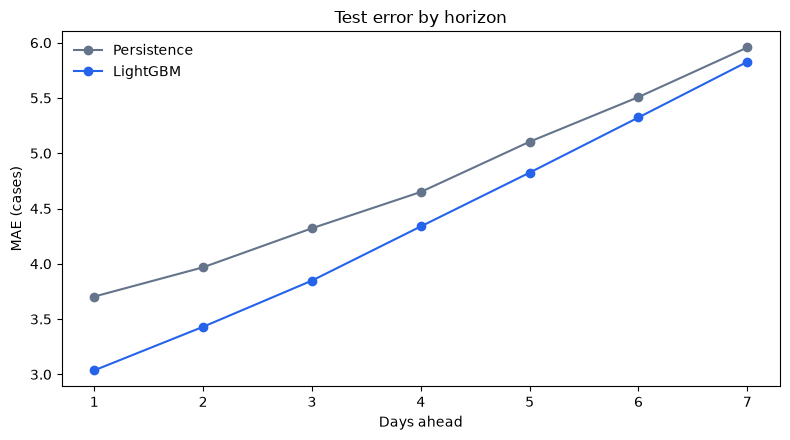

In [3]:
lgb_mae = metrics.loc[metrics.model.eq("LightGBM")].sort_values("horizon_days")
base_mae = metrics.loc[metrics.model.str.startswith("Persistence")].sort_values("horizon_days")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(base_mae.horizon_days, base_mae.MAE, color="#64748B", marker="o", label="Persistence")
ax.plot(lgb_mae.horizon_days, lgb_mae.MAE, color="#2563EB", marker="o", label="LightGBM")
ax.set_xlabel("Days ahead")
ax.set_ylabel("MAE (cases)")
ax.set_xticks(range(1, 8))
ax.set_title("Test error by horizon")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


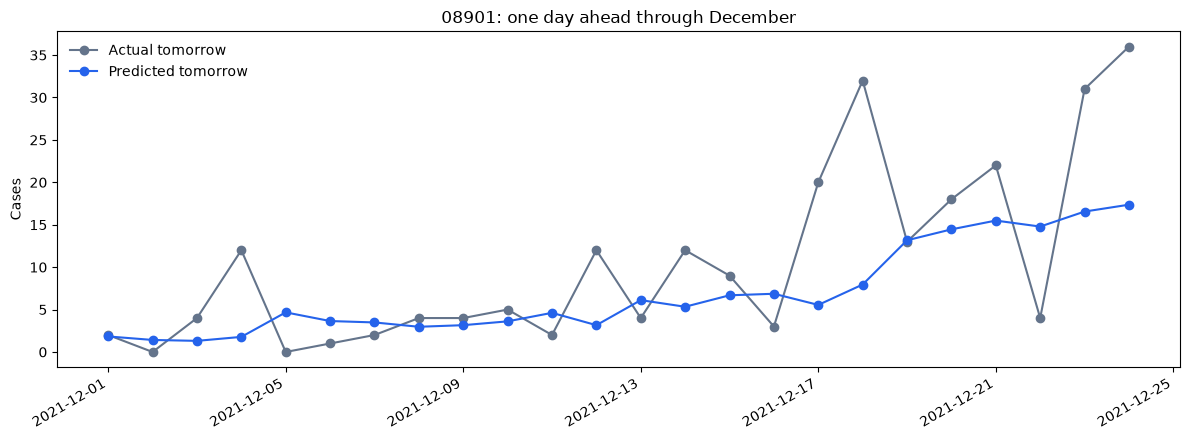

In [4]:
#example = predictions.zipcode.iloc[0]
example = "08901"
one = predictions.loc[predictions.zipcode.eq(example)].sort_values("forecast_date")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(one.forecast_date, one.actual_day_1, color="#64748B", marker="o", label="Actual tomorrow")
ax.plot(one.forecast_date, one.pred_day_1, color="#2563EB", marker="o", label="Predicted tomorrow")
ax.set_title(f"{example}: one day ahead through December")
ax.set_ylabel("Cases")
ax.legend(frameon=False)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()


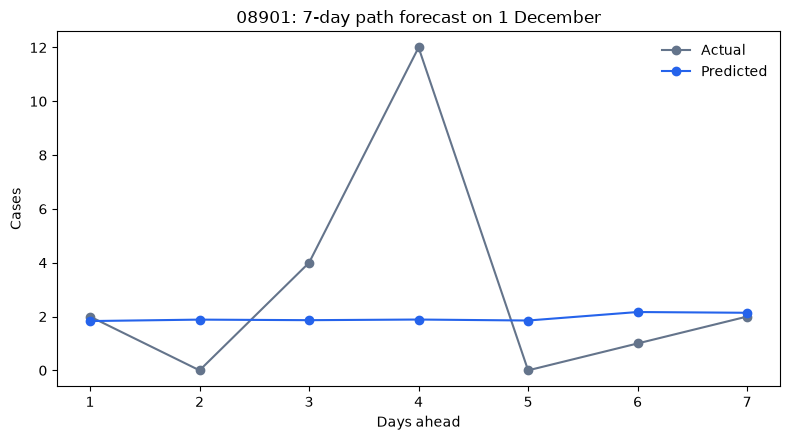

In [5]:
origin = one.loc[one.forecast_date.eq(pd.Timestamp("2021-12-01"))].iloc[0]
days = list(range(1, 8))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(days, [origin[f"actual_day_{d}"] for d in days], color="#64748B", marker="o", label="Actual")
ax.plot(days, [origin[f"pred_day_{d}"] for d in days], color="#2563EB", marker="o", label="Predicted")
ax.set_xticks(days)
ax.set_xlabel("Days ahead")
ax.set_ylabel("Cases")
ax.set_title(f"{example}: 7-day path forecast on 1 December")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## 4. Feature importance

Gain is how much each feature reduced the model's error when it was used for a split. The two charts are tomorrow and a week ahead.


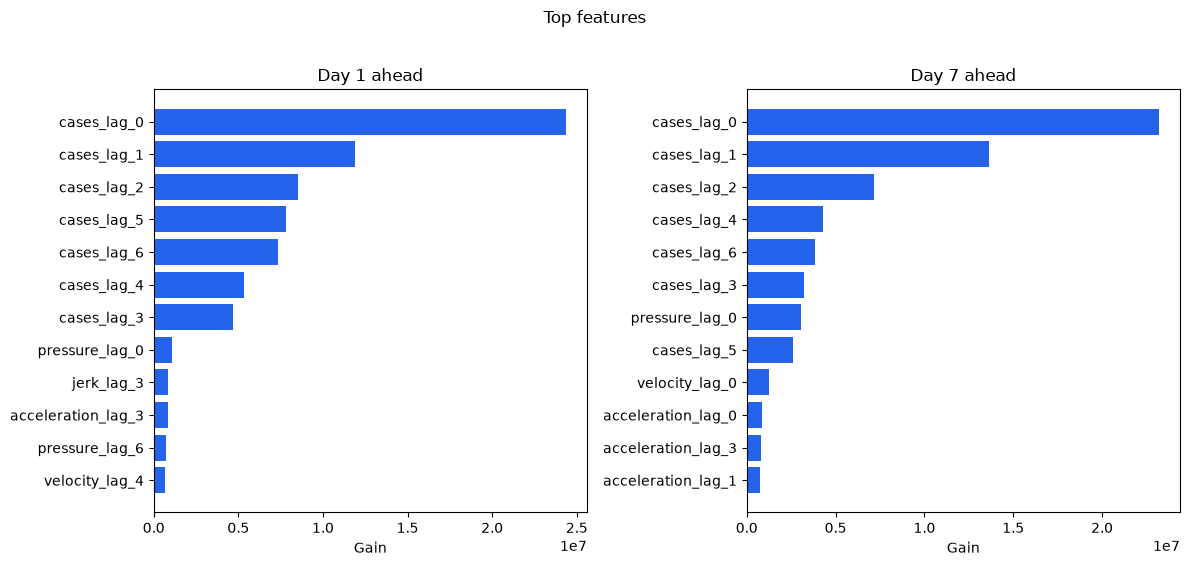

feature          gain
horizon_days                               
1            1    cases_lag_0  2.438173e+07
             2    cases_lag_1  1.190917e+07
             3    cases_lag_2  8.536397e+06
             6    cases_lag_5  7.838019e+06
             7    cases_lag_6  7.355542e+06
2            31   cases_lag_0  1.677255e+07
             35   cases_lag_4  1.226395e+07
             36   cases_lag_5  1.115815e+07
             32   cases_lag_1  1.053673e+07
             34   cases_lag_3  7.223733e+06
3            61   cases_lag_0  1.458475e+07
             65   cases_lag_4  1.413322e+07
             64   cases_lag_3  1.140320e+07
             62   cases_lag_1  9.096106e+06
             63   cases_lag_2  7.656368e+06
4            93   cases_lag_2  1.344361e+07
             94   cases_lag_3  1.323854e+07
             92   cases_lag_1  1.288849e+07
             91   cases_lag_0  1.168953e+07
             95   cases_lag_4  6.648897e+06
5            123  cases_lag_2  1.648351e+07
             121  cases_lag_0  1.547871e+07
             122  cases_lag_1  1.547808e+07
             124  cases_lag_3  5.206285e+06
             126  cases_lag_5  3.535720e+06
6            152  cases_lag_1  1.946500e+07
             151  cases_lag_0  1.892184e+07
             153  cases_lag_2  9.642787e+06
             155  cases_lag_4  3.994361e+06
             154  cases_lag_3  2.971701e+06
7            181  cases_lag_0  2.322576e+07
             182  cases_lag_1  1.362835e+07
             183  cases_lag_2  7.155432e+06
             185  cases_lag_4  4.287659e+06
             187  cases_lag_6  3.814098e+06

In [6]:
importance = feature_importance(models, feature_columns)

def top_gain(horizon, n=12):
    part = importance.loc[importance.horizon_days.eq(horizon)].sort_values("gain", ascending=False).head(n)
    return part.iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, horizon in zip(axes, (1, 7)):
    part = top_gain(horizon)
    ax.barh(part.feature, part.gain, color="#2563EB")
    ax.set_title(f"Day {horizon} ahead")
    ax.set_xlabel("Gain")
fig.suptitle("Top features", y=1.02)
fig.tight_layout()
plt.show()

importance.groupby("horizon_days").apply(lambda g: g.nlargest(5, "gain")[["feature", "gain"]], include_groups=False)
